Displaying generated images:


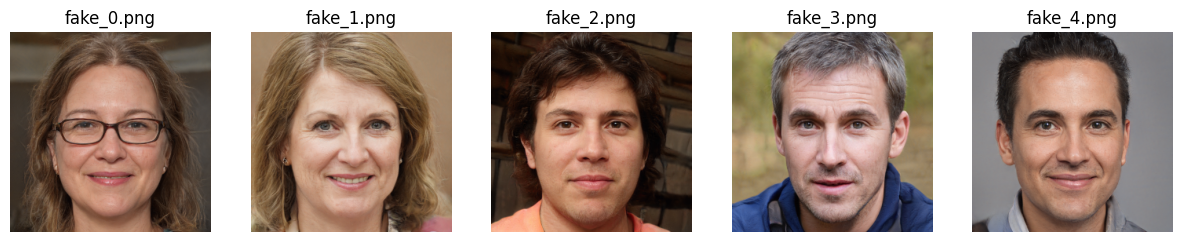

Calculating Inception Score and FID...
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 141MB/s] 


Inception Score (IS): 1.8925
FID Score: 446.9181


In [ ]:
!pip install requests pillow numpy matplotlib torchvision torch scipy

import os
import sys
import subprocess
import torch
import requests
from torch.utils.data import DataLoader
import torchvision.datasets as dsets
import torchvision.transforms as transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.linalg import sqrtm
import torchvision.models as models

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

REPO = 'stylegan2-ada-pytorch'
REPO_URL = 'https://github.com/NVlabs/stylegan2-ada-pytorch.git'
def clone_repo():
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', REPO_URL])
    if os.path.abspath(REPO) not in sys.path:
        sys.path.append(os.path.abspath(REPO))

# Using a verified unauthenticated public link for ffhq.pkl
MODEL_URL = 'https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/transfer-learning-source-nets/ffhq-res256-mirror-paper256-noaug.pkl'
MODEL_PATH = 'ffhq.pkl'

def download_model():
    if os.path.exists(MODEL_PATH) and os.path.getsize(MODEL_PATH) < 10 * 1024 * 1024:
        os.remove(MODEL_PATH)

    if not os.path.exists(MODEL_PATH):
        print("Downloading official ffhq.pkl model from public server...")
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        response = requests.get(MODEL_URL, headers=headers, stream=True, allow_redirects=True)
        response.raise_for_status()
        with open(MODEL_PATH, 'wb') as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
        print("Download finished successfully.")

def generate_images():
    import legacy
    import dnnlib
    G = legacy.load_network_pkl(open(MODEL_PATH, 'rb'))['G_ema'].to(device)
    os.makedirs('generated_images', exist_ok=True)
    imgs = []
    for i in range(10):  # Generate 10 images for stable calculation
        z = torch.randn([1, G.z_dim], device=device)
        label = torch.zeros([1, G.c_dim], device=device)
        img = (G(z, label, truncation_psi=0.5, noise_mode='const') + 1) * 0.5
        save_image(img, f'generated_images/fake_{i}.png')
        imgs.append(img.cpu())
    return torch.cat(imgs)

def display_generated_images():
    print("Displaying generated images:")
    folder = 'generated_images'
    files = sorted([os.path.join(folder, f) for f in os.listdir(folder) if f.endswith('.png')])[:5]

    fig, axes = plt.subplots(1, len(files), figsize=(15, 3))
    if len(files) == 1:
        axes = [axes]
    for ax, fpath in zip(axes, files):
        img = Image.open(fpath)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(os.path.basename(fpath))
    plt.show()

def get_inception_features_and_logits(image_paths):
    # Load standard pretrained Inception v3
    inception = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT, transform_input=False).to(device)
    inception.eval()

    transform = transforms.Compose([
        transforms.Resize((299, 299)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    all_logits = []
    all_features = []

    # Register hook to extract the pool3 (penultimate) feature layer
    features = []
    def hook(module, input, output):
        features.append(output.squeeze(-1).squeeze(-1))

    handle = inception.avgpool.register_forward_hook(hook)

    with torch.no_grad():
        for path in image_paths:
            img = Image.open(path).convert('RGB')
            img_tensor = transform(img).unsqueeze(0).to(device)
            logits = inception(img_tensor)
            all_logits.append(torch.softmax(logits, dim=-1).cpu().numpy())
            all_features.append(features[-1].cpu().numpy())

    handle.remove()
    return np.concatenate(all_logits, axis=0), np.concatenate(all_features, axis=0)

def calculate_metrics():
    print("Calculating Inception Score and FID...")
    fake_paths = [os.path.join('generated_images', f'fake_{i}.png') for i in range(10)]
    real_paths = [os.path.join('real_images', f'real_{i}.png') for i in range(10)]

    try:
        fake_logits, fake_features = get_inception_features_and_logits(fake_paths)
        real_logits, real_features = get_inception_features_and_logits(real_paths)

        # 1. Compute Inception Score (IS)
        # Average marginal distribution p(y)
        p_y = np.expand_dims(np.mean(fake_logits, axis=0), 0)
        # KL Divergence: sum(p(y|x) * (log(p(y|x)) - log(p(y))))
        kl_div = fake_logits * (np.log(fake_logits + 1e-16) - np.log(p_y + 1e-16))
        sum_kl = np.sum(kl_div, axis=1)
        is_score = np.exp(np.mean(sum_kl))
        print(f"Inception Score (IS): {is_score:.4f}")

        # 2. Compute Fréchet Inception Distance (FID)
        mu1, sigma1 = np.mean(fake_features, axis=0), np.cov(fake_features, rowvar=False)
        mu2, sigma2 = np.mean(real_features, axis=0), np.cov(real_features, rowvar=False)

        ssdiff = np.sum((mu1 - mu2) ** 2.0)
        covmean = sqrtm(sigma1.dot(sigma2))
        if np.iscomplexobj(covmean):
            covmean = covmean.real
        fid_score = ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)
        print(f"FID Score: {fid_score:.4f}")
    except Exception as e:
        print(f"Failed to compute metrics: {e}")

def prepare_real_images():
    dataset = dsets.CIFAR10(root='./data', train=True,
    transform=transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(256),
        transforms.ToTensor()
    ]),
    download=True)
    loader = DataLoader(dataset, batch_size=1, shuffle=True)
    os.makedirs('real_images', exist_ok=True)
    for i, (img, _) in enumerate(loader):
        if i >= 10: break
        save_image(img, f"real_images/real_{i}.png")

def main():
    clone_repo()
    download_model()
    generate_images()
    display_generated_images()
    prepare_real_images()
    calculate_metrics()

if __name__ == "__main__":
    main()